In [14]:
import pandas as pd
import numpy as np

In [15]:
url = (
    "https://raw.githubusercontent.com/"
    "DataTalksClub/machine-learning-zoomcamp/main/"
    "cohorts/2026/data/course_lead_scoring_2026.csv"
)

df = pd.read_csv(url)

print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (5000, 9)

Missing values:
lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64


In [16]:
categorical_cols = df.select_dtypes(include="object").columns
numerical_cols = df.select_dtypes(include=np.number).columns

df[categorical_cols] = df[categorical_cols].fillna("NA")
df[numerical_cols] = df[numerical_cols].fillna(0.0)

print("Missing values remaining:", df.isnull().sum().sum())

Missing values remaining: 0


In [17]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(
    df,
    test_size=0.2,
    random_state=1
)

df_train, df_val = train_test_split(
    df_full_train,
    test_size=0.25,
    random_state=1
)

In [18]:
y_train = df_train["converted"]
y_val = df_val["converted"]

X_train = df_train.drop(columns=["converted"])
X_val = df_val.drop(columns=["converted"])

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", df_test.shape)

Train: (3000, 8)
Validation: (1000, 8)
Test: (1000, 9)


# Question 1

In [19]:
from sklearn.metrics import roc_auc_score

numerical_features = [
    "lead_score",
    "number_of_courses_viewed",
    "interaction_count",
    "annual_income"
]

auc_scores = {}

for col in numerical_features:
    auc = roc_auc_score(y_train, X_train[col])

    # Reverse the score direction if AUC is below 0.5
    if auc < 0.5:
        auc = roc_auc_score(y_train, -X_train[col])

    auc_scores[col] = auc

for col, auc in sorted(
    auc_scores.items(),
    key=lambda item: item[1],
    reverse=True
):
    print(f"{col}: {auc:.4f}")

print("\nQ1 answer:", max(auc_scores, key=auc_scores.get))

lead_score: 0.7882
interaction_count: 0.7649
number_of_courses_viewed: 0.7230
annual_income: 0.6082

Q1 answer: lead_score


# Question 2

In [20]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# Convert DataFrames into lists of dictionaries
train_dicts = X_train.to_dict(orient="records")
val_dicts = X_val.to_dict(orient="records")

# One-hot encoding
dv = DictVectorizer(sparse=True)
X_train_encoded = dv.fit_transform(train_dicts)
X_val_encoded = dv.transform(val_dicts)

# Train logistic regression
model = LogisticRegression(
    solver="liblinear",
    C=1.0,
    max_iter=1000
)

model.fit(X_train_encoded, y_train)

# Predict probabilities for the positive class (converted = 1)
y_pred = model.predict_proba(X_val_encoded)[:, 1]

auc = roc_auc_score(y_val, y_pred)
print(f"Validation ROC AUC: {auc:.3f}")

Validation ROC AUC: 0.732


# Question 3

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score

thresholds = np.round(np.arange(101) / 100, 2)

precisions = []
recalls = []

for threshold in thresholds:
    y_pred_binary = (y_pred >= threshold).astype(int)

    precisions.append(
        precision_score(y_val, y_pred_binary, zero_division=0)
    )
    recalls.append(
        recall_score(y_val, y_pred_binary, zero_division=0)
    )

precisions = np.array(precisions)
recalls = np.array(recalls)

# Ignore thresholds where both precision and recall are zero
differences = np.abs(precisions - recalls)
valid = (precisions != 0) | (recalls != 0)
differences[~valid] = np.inf

min_difference = differences.min()
best_thresholds = thresholds[
    np.isclose(differences, min_difference)
]

print("Minimum difference:", min_difference)
print("Threshold(s) where precision and recall are closest:")

Minimum difference: 0.007502647993409384
Threshold(s) where precision and recall are closest:


Threshold=0.63, Precision=0.733, Recall=0.725


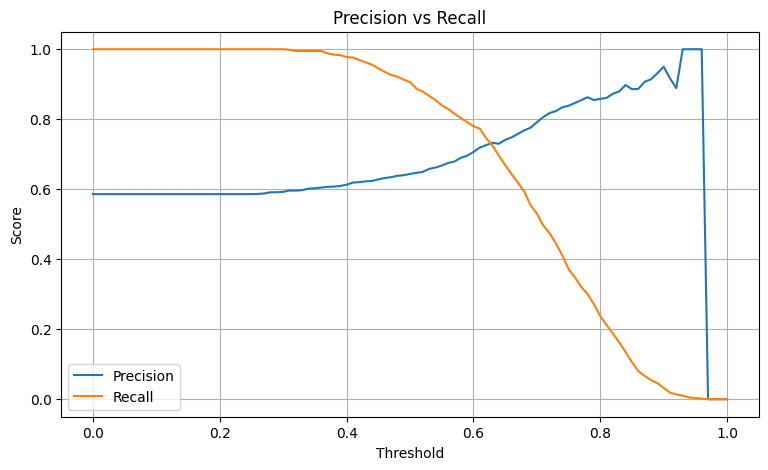

In [22]:
for threshold in best_thresholds:
    i = np.where(thresholds == threshold)[0][0]
    print(
        f"Threshold={threshold:.2f}, "
        f"Precision={precisions[i]:.3f}, "
        f"Recall={recalls[i]:.3f}"
    )

# Plot both curves
plt.figure(figsize=(9, 5))
plt.plot(thresholds, precisions, label="Precision")
plt.plot(thresholds, recalls, label="Recall")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision vs Recall")
plt.legend()
plt.grid(True)
plt.show()

# Question 4

# harmonic mean
\[
F_1 = 2\frac{P \times R}{P + R}
\]

Maximum F1 score: 0.7576
Threshold(s) with maximum F1: [0.41]


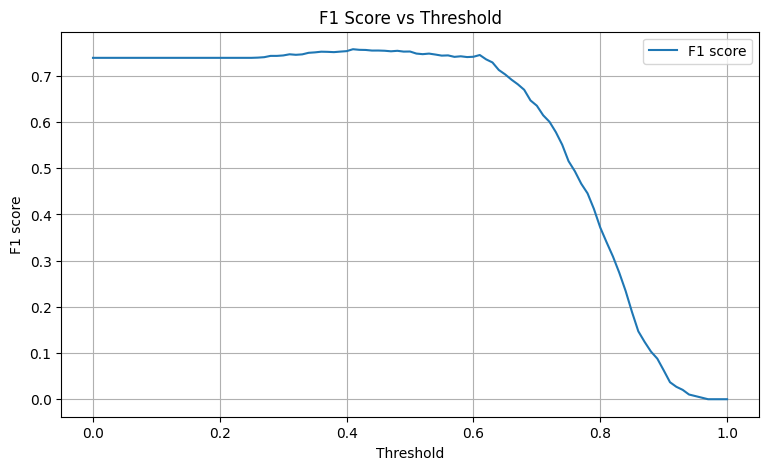

In [23]:
from sklearn.metrics import f1_score

f1_scores = []

for threshold in thresholds:
    y_pred_binary = (y_pred >= threshold).astype(int)

    score = f1_score(
        y_val,
        y_pred_binary,
        zero_division=0
    )

    f1_scores.append(score)

f1_scores = np.array(f1_scores)

max_f1 = f1_scores.max()
best_thresholds = thresholds[
    np.isclose(f1_scores, max_f1)
]

print(f"Maximum F1 score: {max_f1:.4f}")
print("Threshold(s) with maximum F1:", best_thresholds)

plt.figure(figsize=(9, 5))
plt.plot(thresholds, f1_scores, label="F1 score")
plt.xlabel("Threshold")
plt.ylabel("F1 score")
plt.title("F1 Score vs Threshold")
plt.legend()
plt.grid(True)
plt.show()

# Question 5

In [24]:
from sklearn.model_selection import KFold

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

fold_auc_scores = []

for fold, (train_idx, val_idx) in enumerate(
    kf.split(df_full_train), start=1
):
    # Split the full training data into this fold's train/validation sets
    fold_train = df_full_train.iloc[train_idx]
    fold_val = df_full_train.iloc[val_idx]

    y_fold_train = fold_train["converted"]
    y_fold_val = fold_val["converted"]

    X_fold_train = fold_train.drop(columns=["converted"])
    X_fold_val = fold_val.drop(columns=["converted"])

    # Fit the encoder only on this fold's training data
    dv_fold = DictVectorizer(sparse=True)

    X_fold_train_encoded = dv_fold.fit_transform(
        X_fold_train.to_dict(orient="records")
    )
    X_fold_val_encoded = dv_fold.transform(
        X_fold_val.to_dict(orient="records")
    )

    # Train the model
    model_fold = LogisticRegression(
        solver="liblinear",
        C=1.0,
        max_iter=1000
    )

    model_fold.fit(X_fold_train_encoded, y_fold_train)

    # Evaluate this fold
    fold_predictions = model_fold.predict_proba(
        X_fold_val_encoded
    )[:, 1]

    fold_auc = roc_auc_score(y_fold_val, fold_predictions)
    fold_auc_scores.append(fold_auc)

    print(f"Fold {fold}: AUC = {fold_auc:.4f}")

print("\nAll fold scores:", fold_auc_scores)
print(f"Mean AUC: {np.mean(fold_auc_scores):.3f}")
print(f"Standard deviation: {np.std(fold_auc_scores):.3f}")

Fold 1: AUC = 0.7306
Fold 2: AUC = 0.7296
Fold 3: AUC = 0.7363
Fold 4: AUC = 0.7412
Fold 5: AUC = 0.7209

All fold scores: [0.7305601027122453, 0.7295726148196622, 0.7363428071259397, 0.7412454717957564, 0.7209138590326581]
Mean AUC: 0.732
Standard deviation: 0.007


# Question 6

In [25]:
C_values = [0.000001, 0.001, 1]

cv_results = {}

for C in C_values:
    scores = []

    kf = KFold(
        n_splits=5,
        shuffle=True,
        random_state=1
    )

    for train_idx, val_idx in kf.split(df_full_train):
        fold_train = df_full_train.iloc[train_idx]
        fold_val = df_full_train.iloc[val_idx]

        y_fold_train = fold_train["converted"]
        y_fold_val = fold_val["converted"]

        X_fold_train = fold_train.drop(columns=["converted"])
        X_fold_val = fold_val.drop(columns=["converted"])

        dv_fold = DictVectorizer(sparse=True)

        X_fold_train_encoded = dv_fold.fit_transform(
            X_fold_train.to_dict(orient="records")
        )
        X_fold_val_encoded = dv_fold.transform(
            X_fold_val.to_dict(orient="records")
        )

        model_fold = LogisticRegression(
            solver="liblinear",
            C=C,
            max_iter=1000
        )

        model_fold.fit(X_fold_train_encoded, y_fold_train)

        predictions = model_fold.predict_proba(
            X_fold_val_encoded
        )[:, 1]

        scores.append(roc_auc_score(y_fold_val, predictions))

    mean_auc = np.mean(scores)
    std_auc = np.std(scores)

    cv_results[C] = (mean_auc, std_auc)

    print(
        f"C={C:g} | "
        f"Mean AUC={mean_auc:.3f} | "
        f"Std={std_auc:.3f}"
    )

# Highest mean AUC; break ties with lowest std, then smallest C
best_C = sorted(
    C_values,
    key=lambda c: (-cv_results[c][0], cv_results[c][1], c)
)[0]

print("\nBest C:", best_C)

C=1e-06 | Mean AUC=0.617 | Std=0.019
C=0.001 | Mean AUC=0.749 | Std=0.010
C=1 | Mean AUC=0.732 | Std=0.007

Best C: 0.001
